# LaunchLens — decisão de lançamento de aplicativos

Estudo profissional reproduzível com **dados 100% sintéticos**. Alvo: ROI observado em 12 meses ≥20%. A recomendação apoia revisão humana. Nenhuma conclusão comprova viabilidade real.

In [1]:
from pathlib import Path
import sys, json
ROOT = Path.cwd()
if not (ROOT / "pyproject.toml").exists(): ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))
import pandas as pd
from IPython.display import display, Image, Markdown
from launchlens.experiment import run_experiment
from launchlens.data import generate_data, chronological_split
from launchlens.config import FEATURES
historico, candidatos = generate_data()
display(historico.head())
print(historico.shape, candidatos.shape)

(5000, 25) (60, 20)


,app_id,nome_app,data_avaliacao,categoria,plataforma,monetizacao,mercado_mil,crescimento_mercado,concorrentes,diferenciacao,nota_beta,retencao_beta_d7,ativacao_beta,intencao_pagar,preco_mensal,cac_estimado,custo_desenvolvimento,marketing_mensal,experiencia_equipe,prazo_meses,data_desfecho,custo_total_12m,receita_12m,roi_12m,sucesso_12m
0,APP-02316,APP Conceito 2316,2020-01-02,Saude,Android,Freemium,526.77,0.2080,13,7.23,4.56,0.6226,0.5355,0.2428,64.62,30.03,71611.14,9157.30,2,3,2021-01-02,301498.74,498407.62,0.653100,1
1,APP-03674,APP Conceito 3674,2020-01-02,Educacao,Android,Assinatura,1016.28,0.0874,17,2.82,3.14,0.3339,0.6205,0.4841,29.51,25.06,221546.48,11811.07,14,13,2021-01-02,483279.32,524128.67,0.084525,0
2,APP-01488,APP Conceito 1488,2020-01-03,Produtividade,Multiplataforma,Publicidade,201.14,0.1468,17,6.70,3.67,0.6024,0.3484,0.0281,66.11,29.44,169237.09,14716.64,13,9,2021-01-03,465836.77,719705.26,0.544973,1
3,APP-02259,APP Conceito 2259,2020-01-03,Educacao,Multiplataforma,Assinatura,229.25,0.1085,12,5.47,4.23,0.6650,0.4622,0.1136,26.84,11.65,237715.56,11898.27,12,5,2021-01-03,500494.80,1244947.47,1.487433,1
4,APP-02442,APP Conceito 2442,2020-01-03,Financas,Multiplataforma,Freemium,89.44,0.0221,14,4.90,2.55,0.7089,0.7855,0.4286,14.30,98.72,296916.09,5343.27,8,5,2021-01-03,481035.33,1051362.86,1.185625,1


## 1. Entendimento e qualidade dos dados
Cada registro descreve um aplicativo antes do lançamento. Receita e custos futuros definem o alvo, mas não são features. Há ausências simuladas em sinais do beta.

In [2]:
display(historico[FEATURES].describe(include="all").T)
display(historico[FEATURES].isna().mean().sort_values(ascending=False).to_frame("fracao_ausente"))
display(historico.groupby("categoria").sucesso_12m.agg(["count","mean"]))

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
mercado_mil,5000.0,NaN,NaN,NaN,319.392718,243.235653,20.0,154.625,249.39,404.71,2298.86
crescimento_mercado,5000.0,NaN,NaN,NaN,0.123286,0.099134,-0.2,0.0566,0.12275,0.1885,0.4756
concorrentes,5000.0,NaN,NaN,NaN,12.0484,3.514787,2.0,10.0,12.0,14.0,27.0
diferenciacao,5000.0,NaN,NaN,NaN,5.594722,2.10907,0.18,4.02,5.69,7.26,9.97
nota_beta,4907.0,NaN,NaN,NaN,3.67159,0.709988,1.29,3.19,3.74,4.22,4.99
retencao_beta_d7,4904.0,NaN,NaN,NaN,0.430446,0.176974,0.0191,0.29945,0.42465,0.553825,0.9273
ativacao_beta,5000.0,NaN,NaN,NaN,0.624593,0.16067,0.0838,0.513975,0.6374,0.747025,0.9786
intencao_pagar,4902.0,NaN,NaN,NaN,0.28478,0.162422,0.0031,0.158825,0.26215,0.38935,0.8609
preco_mensal,5000.0,NaN,NaN,NaN,44.857744,20.292565,9.91,26.9975,44.77,62.695,79.89
cac_estimado,5000.0,NaN,NaN,NaN,37.274578,20.172876,8.0,23.2875,32.615,46.2925,195.91


,fracao_ausente
intencao_pagar,0.0196
retencao_beta_d7,0.0192
nota_beta,0.0186
mercado_mil,0.0000
crescimento_mercado,0.0000
diferenciacao,0.0000
concorrentes,0.0000
ativacao_beta,0.0000
preco_mensal,0.0000
cac_estimado,0.0000


,count,mean
categoria,,
Educacao,992,0.528226
Entretenimento,947,0.531151
Financas,993,0.544814
Produtividade,1019,0.547596
Saude,1049,0.512869


## 2. Avaliação temporal e maturação
Treino 2020–2021; validação 2023; teste 2025. Os anos 2022 e 2024 ficam em embargo para que os desfechos de 12 meses estejam disponíveis. Pré-processamento é ajustado apenas no treino.

In [3]:
treino, validacao, teste = chronological_split(historico)
for nome, parte in [("treino",treino),("validacao",validacao),("teste",teste)]:
    print(nome, len(parte), parte.data_avaliacao.min(), parte.data_avaliacao.max())
assert treino.data_desfecho.max() < validacao.data_avaliacao.min()
assert validacao.data_desfecho.max() < teste.data_avaliacao.min()

treino 1775 2020-01-02 2021-12-31
validacao 814 2023-01-01 2023-12-30
teste 644 2025-01-03 2025-09-30


## 3. Treinamento e seleção
Comparamos baseline, regressão logística e boosting calibrado. O menor Brier na validação escolhe o vencedor. O corte minimiza custo relativo 2×FP+FN na validação. O teste permanece separado. A execução abaixo gera os artefatos completos usando a mesma implementação da CLI.

In [4]:
resultado = run_experiment(ROOT)
metricas = pd.read_csv(ROOT / "data/processed/metricas_modelos.csv")
display(metricas)
print("Modelo escolhido:", resultado["selected_model"])
print("ROC-AUC teste e IC bootstrap:", resultado["test"]["roc_auc"], resultado["roc_auc_ic95_bootstrap"])

Modelo escolhido: Regressao_Logistica
ROC-AUC teste e IC bootstrap: 0.8046822742474916 [0.7728749675989945, 0.8367054214910208]


,modelo,conjunto,roc_auc,pr_auc_ap,brier,log_loss,acuracia,precisao,recall,f1,tn,fp,fn,tp,n,custo_relativo_por_app,limiar
0,Baseline,validacao,0.500000,0.555283,0.247494,0.688129,0.555283,0.555283,1.000000,0.714060,0,362,0,452,814,0.889435,0.50
1,Regressao_Logistica,validacao,0.816414,0.836370,0.172936,0.516674,0.743243,0.759062,0.787611,0.773073,249,113,96,356,814,0.395577,0.50
2,Gradient_Boosting_Calibrado,validacao,0.802456,0.817176,0.179884,0.538815,0.737101,0.751055,0.787611,0.768898,244,118,96,356,814,0.407862,0.50
3,Regressao_Logistica,teste,0.804682,0.829187,0.179836,0.532189,0.698758,0.821277,0.559420,0.665517,257,42,152,193,644,0.366460,0.68


## 4. Diagnóstico do modelo
ROC e average precision medem discriminação; Brier e calibração avaliam probabilidades. A matriz usa o corte binário, diferente da política de três decisões.

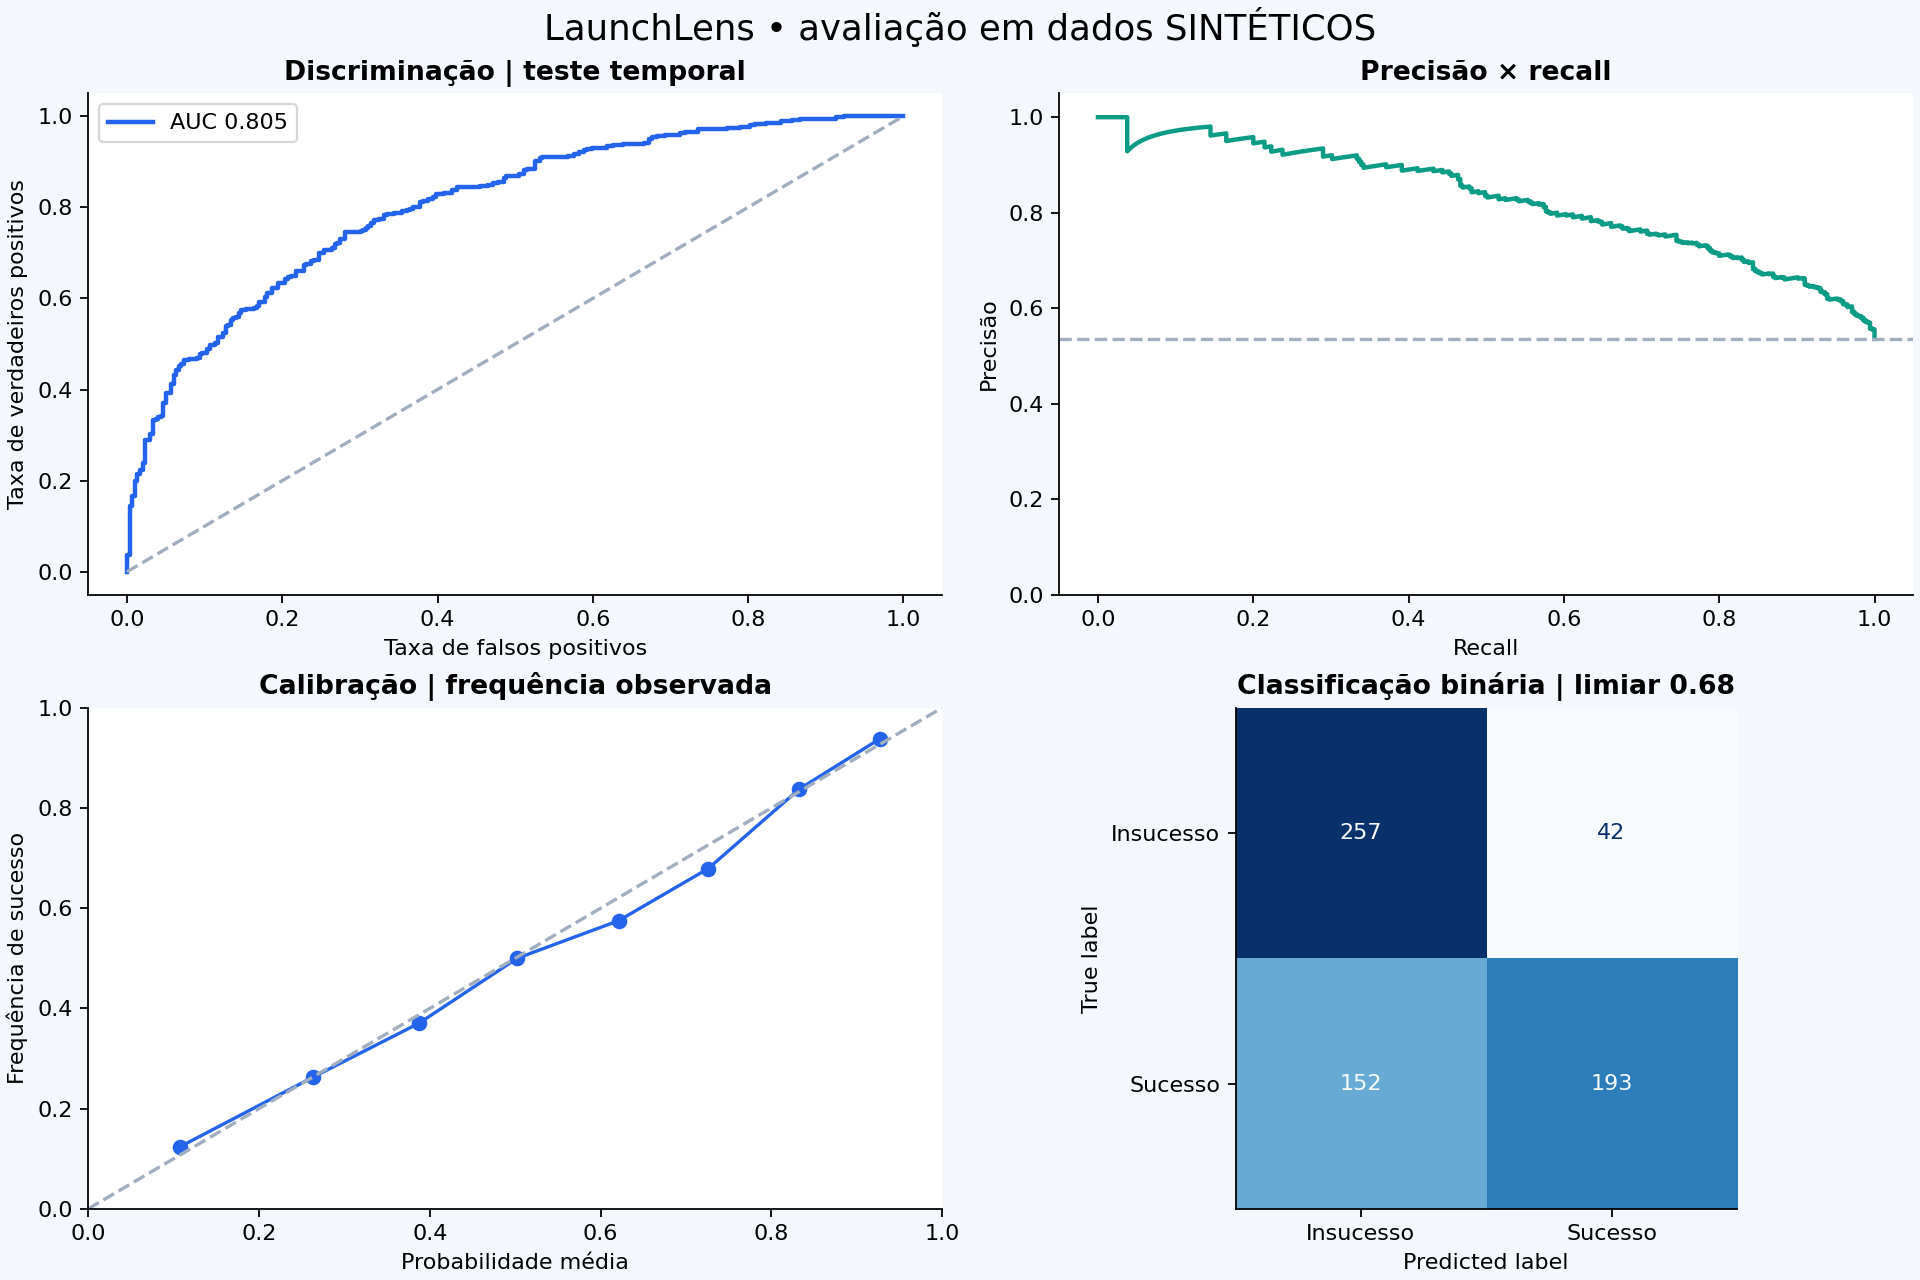

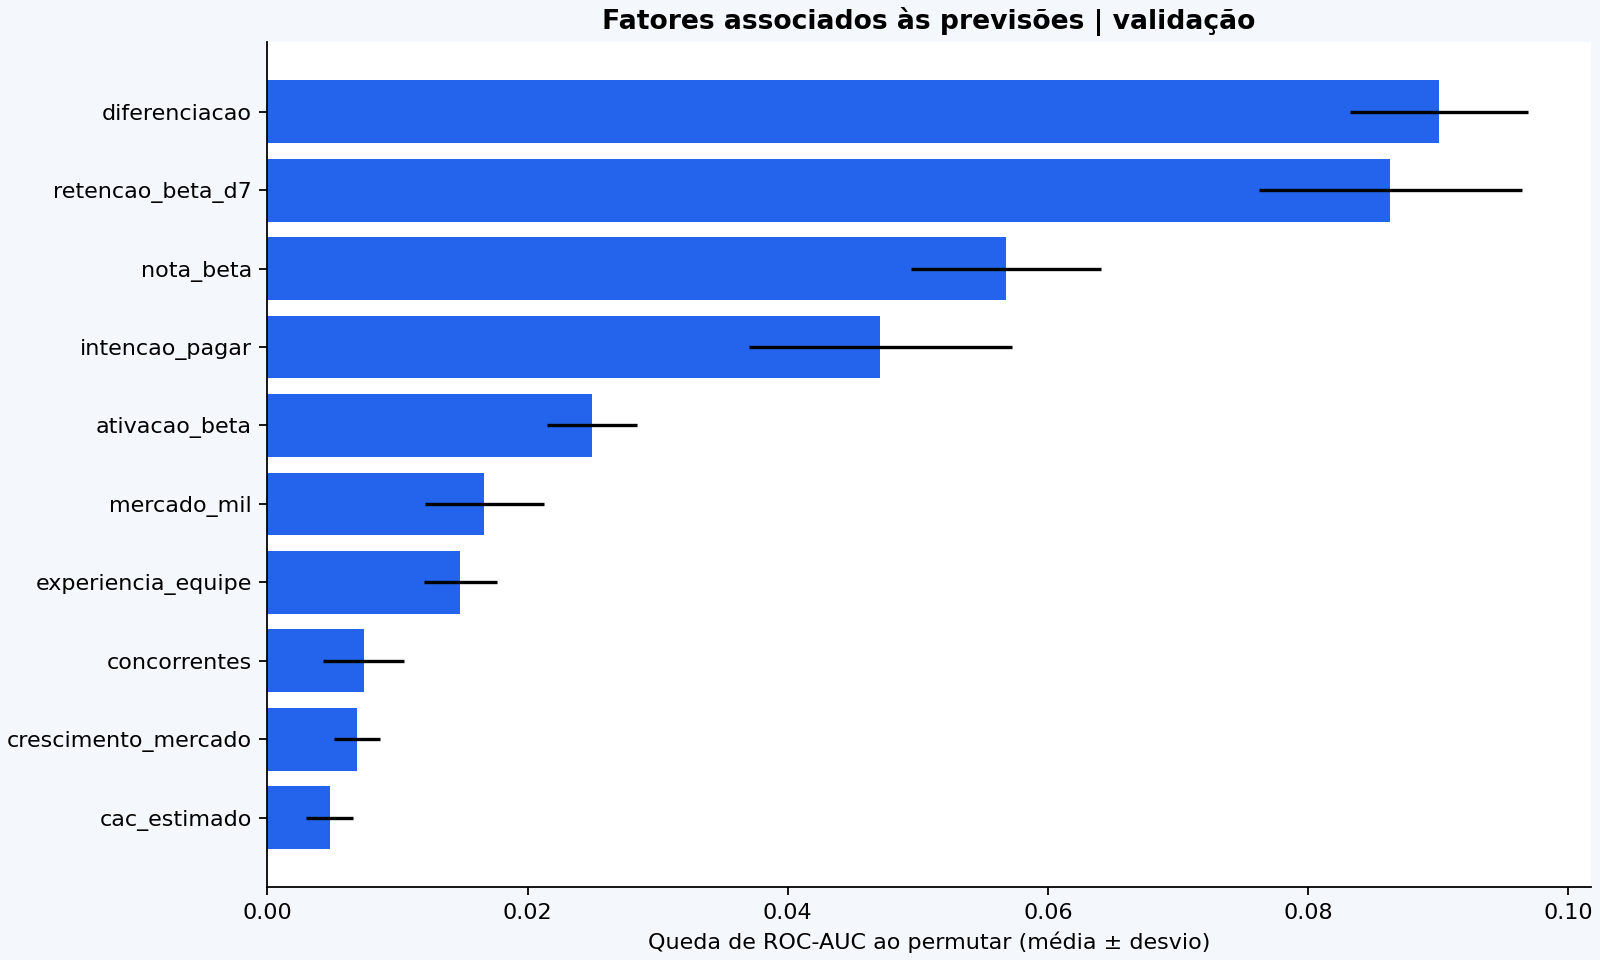

In [5]:
display(Image(filename=str(ROOT / "reports/figures/avaliacao_modelo.png")))
display(Image(filename=str(ROOT / "reports/figures/fatores_modelo.png")))

## 5. Perguntas de negócio e candidatos
O ranking organiza prioridade de investigação. Importância por permutação representa associação preditiva, sem prova de causalidade. A faixa de revisão não é intervalo de confiança.

,ranking,app_id,categoria,prob_sucesso,recomendacao,custo_desenvolvimento
0,1,NOVO-00042,Financas,0.933104,Lancar,167659.78
1,2,NOVO-00038,Financas,0.924986,Lancar,152826.21
2,3,NOVO-00014,Entretenimento,0.922627,Lancar,148301.06
3,4,NOVO-00032,Entretenimento,0.914539,Lancar,104930.08
4,5,NOVO-00003,Produtividade,0.877448,Lancar,279779.29
5,6,NOVO-00039,Saude,0.876552,Lancar,233134.12
6,7,NOVO-00043,Produtividade,0.870748,Lancar,223245.55
7,8,NOVO-00046,Produtividade,0.863449,Lancar,71011.24
8,9,NOVO-00001,Financas,0.836394,Lancar,119949.24
9,10,NOVO-00012,Produtividade,0.822747,Lancar,120502.52


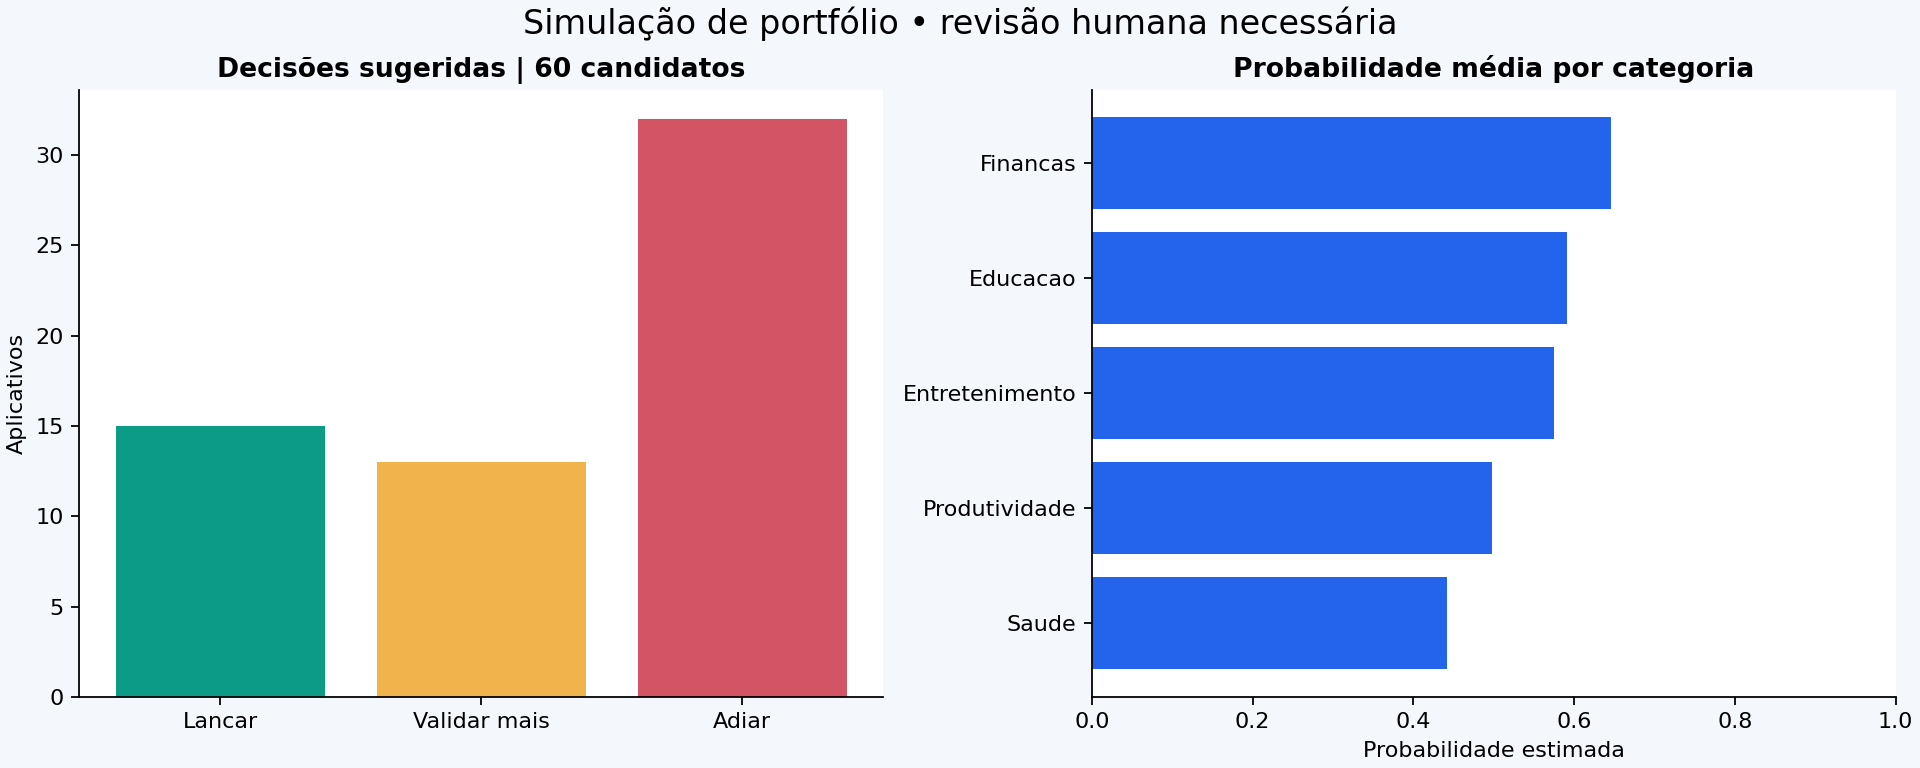

# Resultado executivo — LaunchLens

> Estudo de portfólio com dados 100% fictícios. Não é uma validação de mercado.

## Decisão que o estudo apoia

Priorizar pesquisas e pilotos de aplicativos. O alvo é **ROI observado em 12 meses >=20%**;
a recomendação é uma política aplicada à probabilidade de sucesso, e não uma verdade observada.

## Respostas às perguntas de negócio

1. **Quais aplicativos priorizar?** Dos 60 candidatos, 15 recebem `Lancar`,
   13 recebem `Validar mais` e 32 recebem `Adiar`.
   A tabela abaixo lista os cinco maiores escores; não significa que todos passaram o corte de lançamento.
2. **Que categoria tem maior escore médio?** `Financas` nesta amostra sintética.
   Comparar também a quantidade por categoria; média de grupo pequeno não prova oportunidade real.
3. **O modelo é melhor que uma referência simples?** A tabela de comparação está em
   `data/processed/metricas_modelos.csv`. A seleção por menor Brier na validação escolheu `Regressao_Logistica`.
   Só o vencedor foi avaliado no teste final: ROC-AUC 0.805, Brier 0.180,
   PR-AUC (average precision) 0.829. São métricas do simulador, não do mercado.
4. **Quanto risco há ao classificar?** No teste: 42 falsos positivos e 152 falsos negativos;
   precisão 82.1%, recall 55.9%, no corte binário 0.68.
   Esses números descrevem a classificação binária, que é diferente da política com três decisões.
5. **Quais sinais estão associados às previsões?** Principais variáveis por permutação na validação:
   diferenciacao, retencao_beta_d7, nota_beta, intencao_pagar, ativacao_beta. Associação preditiva não comprova causa nem efeito de uma intervenção.
6. **Quanto capital está associado às propostas?** O painel soma `custo_desenvolvimento` por recomendação;
   trata-se de custo informado antes do lançamento, não lucro esperado ou orçamento otimizado.

| Aplicativo | Categoria | Probabilidade | Recomendação |
| --- | --- | --- | --- |
| NOVO-00042 | Financas | 93.3% | Lancar |
| NOVO-00038 | Financas | 92.5% | Lancar |
| NOVO-00014 | Entretenimento | 92.3% | Lancar |
| NOVO-00032 | Entretenimento | 91.5% | Lancar |
| NOVO-00003 | Produtividade | 87.7% | Lancar |

## Como a política foi definida

O corte binário minimiza `2 × FP + FN` dividido pelo número de casos na validação.
Os pesos são uma hipótese didática, sem unidade monetária. Nenhum lucro esperado é previsto.
Uma margem de 0,10 cria a revisão humana: `Lancar` se p >= 0.78;
`Adiar` se p < 0.58; demais casos recebem `Validar mais`.
A margem é uma regra de governança ilustrativa, não intervalo de confiança.
O IC bootstrap de 95% para ROC-AUC é [0.773, 0.837].
Não é um intervalo individual de probabilidade e assume independência entre aplicativos.

## Próxima decisão humana

Para um caso real, coletar evidências de demanda, custo e retenção em piloto; obter desfechos maduros;
reavaliar seleção dos aplicativos históricos, viés de sobrevivência, custos de erro e calibração.
Não converter estas recomendações sintéticas em autorização de investimento.

## Onde analisar

- `powerbi/LaunchLens.pbip`: portfólio, qualidade do modelo e fatores.
- `notebooks/01_launchlens_end_to_end.ipynb`: investigação executada e reproduzível.
- `reports/figures/`: gráficos exportados do experimento.


In [6]:
pontuados = pd.read_csv(ROOT / "data/processed/candidatos_pontuados.csv")
display(pontuados[["ranking","app_id","categoria","prob_sucesso","recomendacao","custo_desenvolvimento"]].head(15))
display(Image(filename=str(ROOT / "reports/figures/portfolio_candidatos.png")))
display(Markdown((ROOT / "reports/resultado_executivo.md").read_text()))

## 6. Exportação Power BI
O projeto PBIP contém três páginas e cinco tabelas independentes. Os CSVs são embutidos como snapshot portátil. A validação de esquema não substitui abertura e renderização no Power BI Desktop para Windows.

In [7]:
import subprocess
subprocess.run([sys.executable, str(ROOT / "scripts/build_powerbi.py"), "--root", str(ROOT)], check=True)
subprocess.run([sys.executable, str(ROOT / "scripts/validate_powerbi.py")], check=True)

Out[0]: CompletedProcess(args=['/opt/codex/runtimes/codex-primary-runtime/dependencies/python/bin/python', '/workspace/scratch/56d44703dab6/launchlens/scripts/validate_powerbi.py'], returncode=0)


## Conclusão e próximos passos
Os resultados demonstram um processo de ciência de dados reproduzível sobre hipóteses simuladas. Para aplicar a um aplicativo real, obter históricos representativos com desfechos maduros, tratar viés de seleção, reavaliar os custos de erro e validar em um piloto. Consulte `docs/model_card.md` e `docs/metodologia.md`.